# TSLA Machine Learning Trading Model
### Module 3 Project — Predicting TSLA's 30-day price direction to support daily positioning decisions

This notebook follows the **Module 3 Project Assignment** structure. Each numbered section matches a presentation point:

| # | Assignment point | Section in this notebook |
|---|---|---|
| 1 | Problem statement | §1 |
| 2 | Type of ML problem | §2 |
| 3 | Dataset | §3 |
| 4 | EDA findings | §4 |
| 5 | Feature engineering & leakage control | §5 |
| 6 | Models tried (baseline → complex) | §6 |
| 7 | Hyperparameter tuning & findings | §7 |
| 8 | Evaluation metrics & error analysis | §8 |
| 9 | Opportunity sizing | §9 |
| 10 | Deploy / don't-deploy recommendation | §10 |
| 11 | Deployment plan | §11 |
| 12 | GitHub repo & README | §12 (writes `requirements.txt` at the start and generates `README.md` with your results) |

**Run order:** *Kernel → Restart & Run All.* All figures and tables are also saved to `outputs/` for your slides.

## 1. Problem Statement

**Business context.** An investment desk (for example, a small fund or a robo-advisory team) holds Tesla (TSLA) as a core position. Each trading day it must decide how to position TSLA for the coming week: **long, flat, or short**.

**Who is affected?** The portfolio manager who takes the decision, and the clients whose returns and drawdowns depend on it.

**Decision the model supports.** After the market closes on day *t*, the model estimates the probability that TSLA will rise more than +6%, fall more than −6%, or stay in between over the next 30 trading days. A **confidence threshold** turns those probabilities into an action: Buy (long), Sell (short), or Hold (no position).

**How it is handled today (baseline).** The default is passive **buy-and-hold**: always long TSLA, no timing. A machine-learning model is only worth deploying if, **after transaction costs**, it beats buy-and-hold on **risk-adjusted return** (Sharpe ratio) or materially reduces **drawdowns**.

**Success criteria (decided before modelling):**
1. Out-of-sample Sharpe ratio above buy-and-hold, after 0.1% costs per trade.
2. Improvement that is unlikely to be luck (bootstrap confidence interval on excess return above 0).
3. Value created exceeds the cost of building and running the model.

## 2. Type of ML Problem

| Question | Answer | Why |
|---|---|---|
| Supervised or unsupervised? | **Supervised** | Each day has a known outcome (the realised 30-day return), which becomes the label. |
| Classification or regression? | **Classification** | The desk acts on a direction (Buy / Hold / Sell), not an exact return. Predicting exact returns is much noisier. |
| Binary or multi-class? | **Multi-class (3 classes)** | Buy (+1), Hold (0), Sell (−1). Hold matters: it lets the model stay out when it is unsure. |
| Batch or real-time? | **Daily batch** | One prediction per day after the close; no intraday latency requirement. |
| Time series? | **Yes** | Rows are ordered in time, so we **never shuffle**: chronological splits and `TimeSeriesSplit` cross-validation only. |

### Setup 1: libraries and configuration

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             roc_auc_score, classification_report, confusion_matrix)
from xgboost import XGBClassifier  # NEW: needs `pip install xgboost` (see requirements-xgboost.txt)

warnings.filterwarnings("ignore", category=FutureWarning)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({"figure.figsize": (12, 5), "font.size": 10, "axes.titleweight": "bold"})

COLORS = {"strategy": "#2563eb", "buyhold": "#6b7280", -1: "#dc2626", 0: "#9ca3af", 1: "#16a34a"}
CLASS_NAMES = {-1: "Sell (-1)", 0: "Hold (0)", 1: "Buy (1)"}
# --- NEW: XGBoost wrapper -------------------------------------------------
# XGBoost (v3.x) only accepts labels 0..n-1, but this notebook uses -1/0/1.
# A plain XGBClassifier therefore fails with:
#   ValueError: Invalid classes inferred from unique values of `y`.
#   Expected: [0 1 2], got [-1  0  1]
# This thin sklearn-compatible wrapper shifts labels +1 for XGBoost and -1
# back on predict, so .classes_ stays [-1, 0, 1] and predict_proba columns
# line up with it, exactly like the other candidates. It works with
# clone() and GridSearchCV, which the notebook uses in sections 6.1-6.2.
# NOTE: unlike the sklearn models, XGBClassifier has no class_weight="balanced"
# option, so XGBoost runs without balanced class weights.
class XGBoostShifted(BaseEstimator, ClassifierMixin):
    def __init__(self, n_estimators=200, max_depth=3, learning_rate=0.05,
                 subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                 random_state=42, n_jobs=-1):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.learning_rate = learning_rate
        self.subsample = subsample
        self.colsample_bytree = colsample_bytree
        self.reg_lambda = reg_lambda
        self.random_state = random_state
        self.n_jobs = n_jobs

    def fit(self, X, y, **kw):
        y = np.asarray(y)
        self.classes_ = np.array(sorted(set(y.tolist())))
        self.model_ = XGBClassifier(
            n_estimators=self.n_estimators, max_depth=self.max_depth,
            learning_rate=self.learning_rate, subsample=self.subsample,
            colsample_bytree=self.colsample_bytree, reg_lambda=self.reg_lambda,
            eval_metric="mlogloss", random_state=self.random_state, n_jobs=self.n_jobs)
        self.model_.fit(X, y + 1, **kw)
        return self

    def predict(self, X, **kw):
        return self.model_.predict(X, **kw) - 1

    def predict_proba(self, X, **kw):
        return self.model_.predict_proba(X, **kw)


In [2]:
# ==========================================
# ADJUSTABLE PROJECT PARAMETERS
# ==========================================
TICKER          = "TSLA"
START_DATE      = "2012-01-01"
END_DATE        = "2026-10-01"   # Ends test period at 2026-10-01
VAL_START       = "2021-01-01"   # Validation covers 2021 to 2022
TEST_START      = "2023-01-01"   # Test covers 2023 through 2026-10-01

# Target definition
FUTURE_PERIOD   = 30            # look-ahead horizon in trading days
BUY_THRESHOLD   = 0.06          # future return > +6%  -> Buy (1)
SELL_THRESHOLD  = -0.06         # future return < -6%  -> Sell (-1)

# Backtest assumptions
INITIAL_CAPITAL = 100_000.0
TRANSACTION_FEE = 0.001          # 0.1% per unit of position change (fees + slippage)
RISK_FREE_RATE  = 0.02           # annual, for Sharpe / Sortino
EXECUTION_LAG   = 2              # signal after close on day t, filled at close of t+1 (see §6)
LONG_ONLY       = False          # True = Sell signals mean "go flat" instead of "go short"
DEFAULT_CONFIDENCE = 0.45        # starting confidence threshold (tuned on validation in §7)
MIN_TRADES      = 6              # threshold search ignores settings with fewer position changes

# Modelling
RANDOM_STATE    = 42
N_CV_SPLITS     = 5
SELECTION_METRIC = "Sharpe"      # how the final model is chosen on validation: "Sharpe" or "Macro F1"

# Outputs (used by README / slides)
OUTPUT_DIR, FIG_DIR, DATA_DIR = "outputs", "outputs/figures", "data"
for d in (OUTPUT_DIR, FIG_DIR, DATA_DIR):
    os.makedirs(d, exist_ok=True)

def save_fig(name):
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")

np.random.seed(RANDOM_STATE)
print(f"{TICKER}: horizon {FUTURE_PERIOD}d | Buy > {BUY_THRESHOLD:+.1%} | Sell < {SELL_THRESHOLD:+.1%} | "
      f"fee {TRANSACTION_FEE:.1%} | long-only={LONG_ONLY}")

TSLA: horizon 30d | Buy > +6.0% | Sell < -6.0% | fee 0.1% | long-only=False


## 3. Dataset

**Source.** Daily OHLCV (open, high, low, close, volume) bars for TSLA from Yahoo Finance via the `yfinance` library, **split- and dividend-adjusted** (`auto_adjust=True`). Adjustment matters: TSLA had a 5:1 split in 2020 and a 3:1 split in 2022, which would otherwise look like 75–86% one-day crashes.

**Reproducibility.** The first successful download is cached to `data/tsla_ohlcv.csv`; later runs read the cache, so results do not change when Yahoo revises data.

**Offline fallback.** If Yahoo cannot be reached, the notebook generates a **synthetic** random-walk series so the code still runs. Synthetic data has **no real patterns**, so its results must not be presented. The notebook prints a clear warning whenever this happens.

In [3]:
CACHE_FILE = f"{DATA_DIR}/{TICKER.lower()}_ohlcv.csv"

def download_yahoo():
    import yfinance as yf
    df = yf.download(TICKER, start=START_DATE, end=END_DATE, auto_adjust=True, progress=False)
    if df is None or df.empty:                    # yfinance often returns an EMPTY frame instead of raising
        raise ValueError("yfinance returned no rows (network blocked or ticker unavailable)")
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    df = df[["Open", "High", "Low", "Close", "Volume"]].dropna()
    df.index = pd.to_datetime(df.index).tz_localize(None)
    df.index.name = "Date"
    return df

def make_synthetic():
    rng = np.random.default_rng(RANDOM_STATE)
    dates = pd.bdate_range(START_DATE, END_DATE, inclusive="left")
    n = len(dates)
    rets = rng.normal(0.0008, 0.018, n)
    close = 15.0 * np.exp(np.cumsum(rets))
    high = close * (1 + np.abs(rng.normal(0, 0.008, n)))
    low = close * (1 - np.abs(rng.normal(0, 0.008, n)))
    open_ = low + (high - low) * rng.uniform(0.1, 0.9, n)
    vol = rng.integers(40_000_000, 120_000_000, n)
    return pd.DataFrame({"Open": open_, "High": high, "Low": low, "Close": close, "Volume": vol},
                        index=pd.DatetimeIndex(dates, name="Date"))

def load_data():
    if os.path.exists(CACHE_FILE):
        return pd.read_csv(CACHE_FILE, index_col="Date", parse_dates=True), "Yahoo Finance (cached)"
    try:
        df = download_yahoo()
        df.to_csv(CACHE_FILE)
        return df, "Yahoo Finance (downloaded)"
    except Exception as e:
        print(f"WARNING: could not download real data -> using SYNTHETIC data. Reason: {e}")
        return make_synthetic(), "SYNTHETIC (offline fallback)"

df_raw, DATA_SOURCE = load_data()
IS_SYNTHETIC = DATA_SOURCE.startswith("SYNTHETIC")

print(f"Source : {DATA_SOURCE}")
print(f"Rows   : {len(df_raw):,} trading days   Columns: {list(df_raw.columns)}")
print(f"Period : {df_raw.index.min():%Y-%m-%d} to {df_raw.index.max():%Y-%m-%d}")
print(f"Missing values per column:\n{df_raw.isna().sum().to_string()}")
if IS_SYNTHETIC:
    print("\n" + "!" * 80 + "\n  SYNTHETIC DATA: results below are for testing the code only. Re-run with internet access.\n" + "!" * 80)
df_raw.describe().round(2)

Source : Yahoo Finance (downloaded)
Rows   : 3,707 trading days   Columns: ['Open', 'High', 'Low', 'Close', 'Volume']
Period : 2012-01-03 to 2026-09-30
Missing values per column:
Price
Open      0
High      0
Low       0
Close     0
Volume    0


Price,Open,High,Low,Close,Volume
count,3707.00,3707.00,3707.00,3707.00,3.707000e+03
mean,123.85,126.48,121.07,123.82,1.023018e+08
std,138.77,141.62,135.70,138.69,7.385095e+07
min,1.77,1.79,1.51,1.52,5.473500e+06
25%,14.77,15.00,14.53,14.72,5.845350e+07
50%,22.89,23.24,22.46,22.89,8.612400e+07
75%,236.00,240.91,232.27,236.92,1.234976e+08
max,489.88,498.83,485.33,489.88,9.140820e+08


### 3.1 Target variable

For each day *t*, the future 30-day return is

$$R_{t \to t+N} = \frac{\text{Close}_{t+N}}{\text{Close}_t} - 1, \qquad N = 30$$

| Label | Rule | Meaning |
|---|---|---|
| **Buy (+1)** | $R > +6\%$ | worth being long |
| **Sell (−1)** | $R < -6\%$ | worth being short / out |
| **Hold (0)** | otherwise | move too small to cover costs and risk |

The ±6% band is set so that a correct signal clears the round-trip transaction cost with room to spare. The last *N* rows have no future price yet, so they are dropped.

In [4]:
def create_target(df, horizon=FUTURE_PERIOD, buy_thresh=BUY_THRESHOLD, sell_thresh=SELL_THRESHOLD):
    data = df.copy()
    data["Future_Return"] = data["Close"].shift(-horizon) / data["Close"] - 1.0   # uses the FUTURE: label only
    data = data.dropna(subset=["Future_Return"])
    data["Target"] = np.select([data["Future_Return"] > buy_thresh,
                                data["Future_Return"] < sell_thresh], [1, -1], default=0)
    return data

df_target = create_target(df_raw)
dist = df_target["Target"].value_counts(normalize=True).sort_index().rename(CLASS_NAMES)
print("Overall class distribution:\n" + dist.map("{:.1%}".format).to_string())

Overall class distribution:
Target
Sell (-1)    31.1%
Hold (0)     26.0%
Buy (1)      42.9%


## 4. Exploratory Data Analysis

Four key findings, each linked to a modelling decision. (With real data, check the printed numbers match the descriptions before presenting them.)

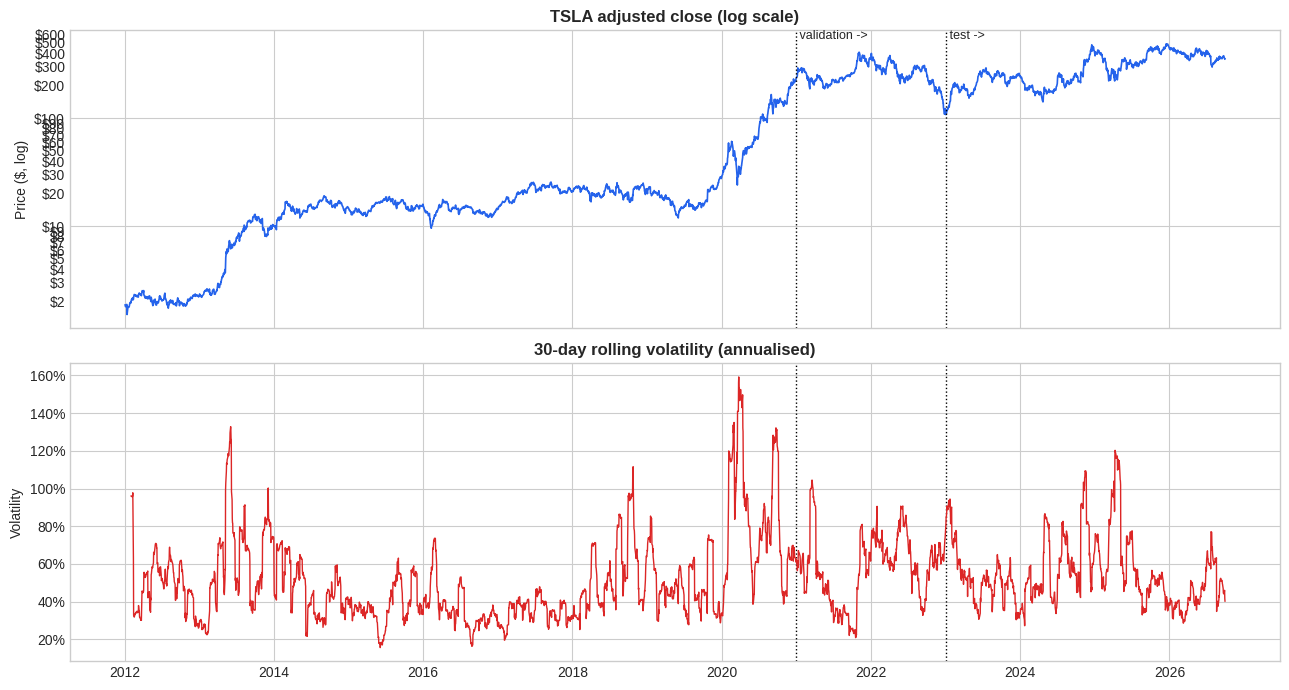

Price grew 189.5x over the period.
Rolling volatility ranged from 16% to 159% (median 48%).


In [5]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(df_raw.index, df_raw["Close"], color=COLORS["strategy"], lw=1.2)
axes[0].set_yscale("log")
axes[0].set_title(f"{TICKER} adjusted close (log scale)")
axes[0].set_ylabel("Price ($, log)")
for d, lbl in [(VAL_START, "validation ->"), (TEST_START, "test ->")]:
    for ax in axes:
        ax.axvline(pd.Timestamp(d), color="black", ls=":", lw=1)
    axes[0].text(pd.Timestamp(d), axes[0].get_ylim()[1], " " + lbl, va="top", fontsize=9)

daily_ret = df_raw["Close"].pct_change()
roll_vol = daily_ret.rolling(20).std() * np.sqrt(252)
axes[1].plot(roll_vol.index, roll_vol, color=COLORS[-1], lw=1)
axes[1].set_title("30-day rolling volatility (annualised)")
axes[1].set_ylabel("Volatility")
from matplotlib.ticker import FuncFormatter, PercentFormatter
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))
axes[0].yaxis.set_minor_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
plt.tight_layout(); save_fig("eda_1_price_and_volatility"); plt.show()

print(f"Price grew {df_raw['Close'].iloc[-1] / df_raw['Close'].iloc[0]:.1f}x over the period.")
print(f"Rolling volatility ranged from {roll_vol.min():.0%} to {roll_vol.max():.0%} (median {roll_vol.median():.0%}).")

**Finding 1: Prices are non-stationary; volatility comes in regimes.**
The price level rises many-fold, so a raw price (or anything in dollars) means something different in 2013 than in 2024. Volatility is not constant: calm periods alternate with turbulent ones (for example, the 2020 crash and 2022 sell-off in real data).

➡ **Modelling choice:** use only **scale-free features** (returns, ratios to moving averages, and MACD *divided by price*), and add **volatility features**. Error analysis in §8 is split by **volatility regime**.

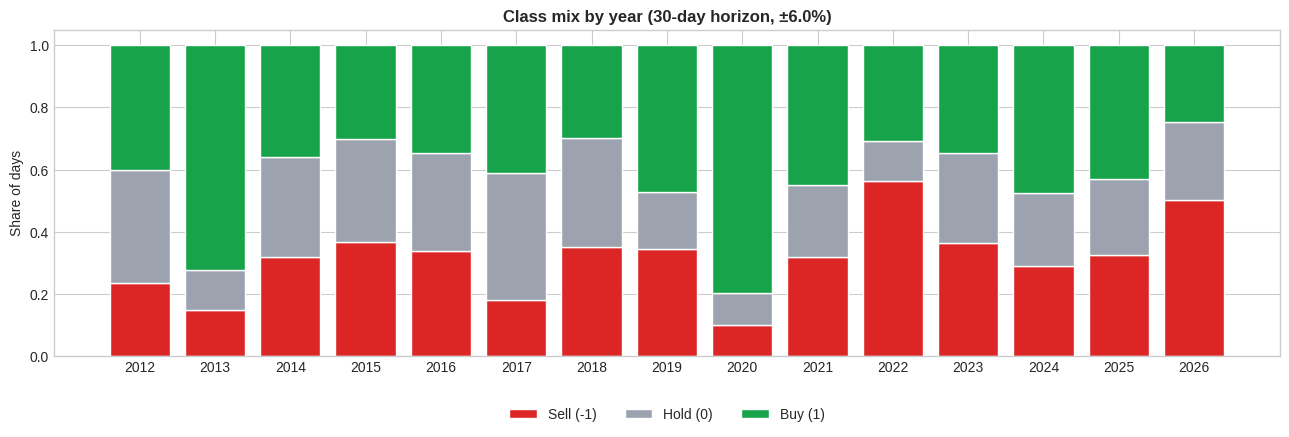

Target Sell (-1) Hold (0) Buy (1)
Date                             
2012         24%      36%     40%
2013         15%      13%     72%
2014         32%      32%     36%
2015         37%      33%     30%
2016         34%      32%     35%
2017         18%      41%     41%
2018         35%      35%     30%
2019         35%      18%     47%
2020         10%      10%     80%
2021         32%      23%     45%
2022         56%      13%     31%
2023         36%      29%     35%
2024         29%      23%     48%
2025         32%      24%     43%
2026         50%      25%     25%


In [6]:
by_year = (df_target.groupby(df_target.index.year)["Target"]
           .value_counts(normalize=True).unstack().reindex(columns=[-1, 0, 1]).fillna(0))
fig, ax = plt.subplots(figsize=(13, 4.5))
bottom = np.zeros(len(by_year))
for c in [-1, 0, 1]:
    ax.bar(by_year.index.astype(str), by_year[c], bottom=bottom, color=COLORS[c], label=CLASS_NAMES[c], edgecolor="white")
    bottom += by_year[c].values
ax.set_title(f"Class mix by year ({FUTURE_PERIOD}-day horizon, ±{BUY_THRESHOLD:.1%})")
ax.set_ylabel("Share of days"); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); save_fig("eda_2_class_mix_by_year"); plt.show()
print(by_year.rename(columns=CLASS_NAMES).map("{:.0%}".format).to_string())

**Finding 2: The three classes are roughly balanced overall, but the mix shifts from year to year.**
No class is tiny, yet bull years tilt towards Buy and bear years (such as 2022) towards Sell. A model trained on mostly bullish years may over-predict Buy.

➡ **Modelling choice:** `class_weight="balanced"`; judge models on **macro F1** (every class counts equally) rather than accuracy; compare against a **majority-class baseline**; check performance **per period** in error analysis.

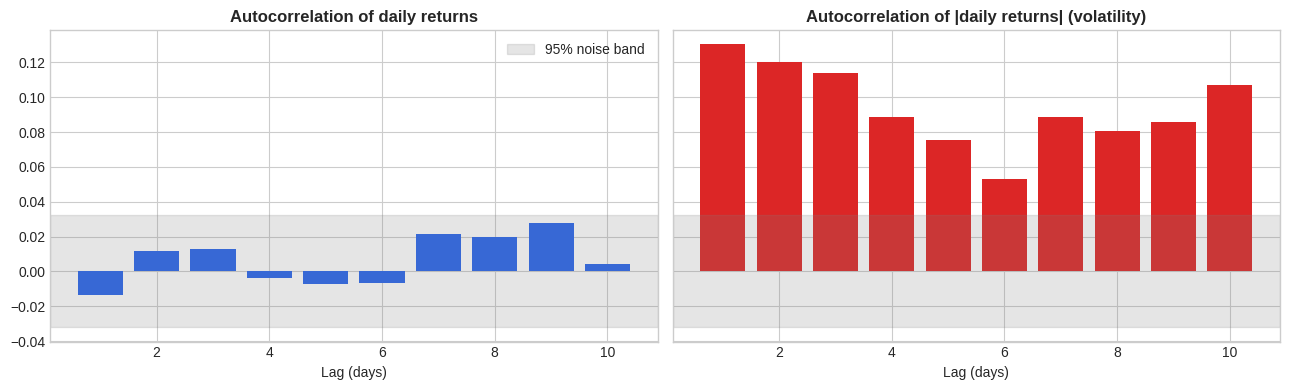

Mean |autocorr| of returns, lags 1-10: 0.013  (noise band ±0.032)
Mean autocorr of |returns|, lags 1-10: 0.094


In [7]:
lags = range(1, 11)
acf_ret = [daily_ret.autocorr(l) for l in lags]
acf_abs = [daily_ret.abs().autocorr(l) for l in lags]
conf = 1.96 / np.sqrt(daily_ret.notna().sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
axes[0].bar(list(lags), acf_ret, color=COLORS["strategy"])
axes[0].set_title("Autocorrelation of daily returns")
axes[1].bar(list(lags), acf_abs, color=COLORS[-1])
axes[1].set_title("Autocorrelation of |daily returns| (volatility)")
for ax in axes:
    ax.axhspan(-conf, conf, color="grey", alpha=0.2, label="95% noise band")
    ax.set_xlabel("Lag (days)")
axes[0].legend()
plt.tight_layout(); save_fig("eda_3_autocorrelation"); plt.show()
print(f"Mean |autocorr| of returns, lags 1-10: {np.mean(np.abs(acf_ret)):.3f}  (noise band ±{conf:.3f})")
print(f"Mean autocorr of |returns|, lags 1-10: {np.mean(acf_abs):.3f}")

**Finding 3: Direction is close to unpredictable from past returns alone; volatility is much more predictable.**
Return autocorrelations sit mostly inside the noise band, while absolute returns are positively autocorrelated (volatility clustering) in real market data.

➡ **Modelling choice:** expect only a **small edge**. Use **regularised, shallow models** to avoid fitting noise; insist on beating simple **baselines**; use a **Hold** class and a **confidence threshold** so the model only trades when it is relatively sure.

## 5. Feature Engineering and Leakage Control

All features use **only information available at the close of day *t***: rolling windows and exponential averages look backwards, and nothing uses `shift(-k)`. Only the **target** looks forward.

| Group | Features | Reasoning |
|---|---|---|
| Momentum | `Return_1D/5D/10D/21D/63D` | Recent trend over a day, week, fortnight, month, quarter |
| Trend position | `Ratio_SMA10/50/200`, `Dist_52W_High` | Where price sits relative to its averages / yearly high |
| Oscillators | `RSI_14`, `BB_PctB` | Overbought / oversold signals |
| MACD (normalised) | `MACD_Pct`, `MACD_Signal_Pct`, `MACD_Hist_Pct` | **Changed from the original**: raw MACD is in dollars and grows with price (Finding 1), so it is divided by price |
| Volatility | `Vol_20D`, `Vol_Ratio_20_60`, `HL_Range_14` | Volatility level and whether it is rising; intraday range |
| Volume | `Volume_Ratio` | Unusual trading activity |

**Cleaning.** Rows in the warm-up period (first ~252 days, needed for the 52-week high and 200-day average) are dropped; there are no other missing values. **Scaling** is applied only to Logistic Regression, inside a `Pipeline`, so the scaler is fitted on training folds only. Tree models do not need scaling. There are no categorical columns, so no encoding is needed.

In [8]:
def build_features(df):
    d = df.copy()
    c = d["Close"]
    # Momentum
    for n in (1, 5, 10, 21, 63):
        d[f"Return_{n}D"] = c.pct_change(n)
    # Trend position
    for n in (10, 50, 200):
        d[f"Ratio_SMA{n}"] = c / c.rolling(n).mean()
    d["Dist_52W_High"] = c / c.rolling(252).max() - 1
    # RSI (14)
    delta = c.diff()
    gain = delta.clip(lower=0).rolling(14).mean()
    loss = (-delta.clip(upper=0)).rolling(14).mean()
    d["RSI_14"] = 100 - 100 / (1 + gain / (loss + 1e-8))
    # MACD, normalised by price so it is comparable across years
    macd = c.ewm(span=12, adjust=False).mean() - c.ewm(span=26, adjust=False).mean()
    signal = macd.ewm(span=9, adjust=False).mean()
    d["MACD_Pct"], d["MACD_Signal_Pct"], d["MACD_Hist_Pct"] = macd / c, signal / c, (macd - signal) / c
    # Bollinger %B
    mid, sd = c.rolling(20).mean(), c.rolling(20).std()
    d["BB_PctB"] = (c - (mid - 2 * sd)) / (4 * sd + 1e-8)
    # Volatility
    r = c.pct_change()
    d["Vol_20D"] = r.rolling(20).std()
    d["Vol_Ratio_20_60"] = d["Vol_20D"] / (r.rolling(60).std() + 1e-8)
    d["HL_Range_14"] = ((d["High"] - d["Low"]) / c).rolling(14).mean()
    # Volume
    d["Volume_Ratio"] = d["Volume"] / (d["Volume"].rolling(20).mean() + 1e-8)
    return d

FEATURE_COLS = ["Return_1D", "Return_5D", "Return_10D", "Return_21D", "Return_63D",
                "Ratio_SMA10", "Ratio_SMA50", "Ratio_SMA200", "Dist_52W_High",
                "RSI_14", "MACD_Pct", "MACD_Signal_Pct", "MACD_Hist_Pct", "BB_PctB",
                "Vol_20D", "Vol_Ratio_20_60", "HL_Range_14", "Volume_Ratio"]

df_model = create_target(build_features(df_raw))
df_model = df_model.dropna(subset=FEATURE_COLS)
print(f"Modelling table: {len(df_model):,} rows x {len(FEATURE_COLS)} features "
      f"({df_model.index.min():%Y-%m-%d} to {df_model.index.max():%Y-%m-%d})")

# Leakage self-check: features computed on data truncated at day t must equal features computed on the full history
t = df_raw.index[len(df_raw) // 2]
full_row = build_features(df_raw).loc[t, FEATURE_COLS]
trunc_row = build_features(df_raw.loc[:t]).loc[t, FEATURE_COLS]
assert np.allclose(full_row.values, trunc_row.values, equal_nan=True), "Look-ahead leakage detected!"
print(f"Leakage check passed: features on {t:%Y-%m-%d} are identical with or without future data.")

Modelling table: 3,426 rows x 18 features (2013-01-03 to 2026-08-18)
Leakage check passed: features on 2019-05-16 are identical with or without future data.


### 5.1 Chronological split with purging

Train 2012–2020 · Validation 2021–2022 · Test 2023–2026 (sealed).

**Why purge?** A label on 28 Dec 2020 depends on prices up to early January 2021, which fall inside the validation period. Keeping it in training would leak validation information. We therefore **drop the last `FUTURE_PERIOD` rows before each boundary**. Cross-validation uses `TimeSeriesSplit(gap=FUTURE_PERIOD)` for the same reason.

In [9]:
def purged_index(df, end, start=None, purge=FUTURE_PERIOD):
    idx = df.index[df.index < pd.Timestamp(end)]
    if start is not None:
        idx = idx[idx >= pd.Timestamp(start)]
    return idx[:-purge] if purge > 0 else idx

train_idx = purged_index(df_model, VAL_START)
val_idx   = purged_index(df_model, TEST_START, start=VAL_START)
test_idx  = df_model.index[df_model.index >= pd.Timestamp(TEST_START)]
trval_idx = purged_index(df_model, TEST_START)          # used only for the final refit in §8

X_train, y_train = df_model.loc[train_idx, FEATURE_COLS], df_model.loc[train_idx, "Target"]
X_val,   y_val   = df_model.loc[val_idx,   FEATURE_COLS], df_model.loc[val_idx,   "Target"]
X_test,  y_test  = df_model.loc[test_idx,  FEATURE_COLS], df_model.loc[test_idx,  "Target"]

split_summary = pd.DataFrame({
    "Rows": [len(train_idx), len(val_idx), len(test_idx)],
    "From": [i.min().date() for i in (train_idx, val_idx, test_idx)],
    "To":   [i.max().date() for i in (train_idx, val_idx, test_idx)],
    **{CLASS_NAMES[c]: [f"{(y == c).mean():.0%}" for y in (y_train, y_val, y_test)] for c in (-1, 0, 1)},
}, index=["Train", "Validation", "Test (sealed)"])
split_summary

,Rows,From,To,Sell (-1),Hold (0),Buy (1)
Train,1984,2013-01-03,2020-11-17,27%,27%,46%
Validation,473,2021-01-04,2022-11-16,43%,19%,37%
Test (sealed),909,2023-01-03,2026-08-18,36%,25%,39%


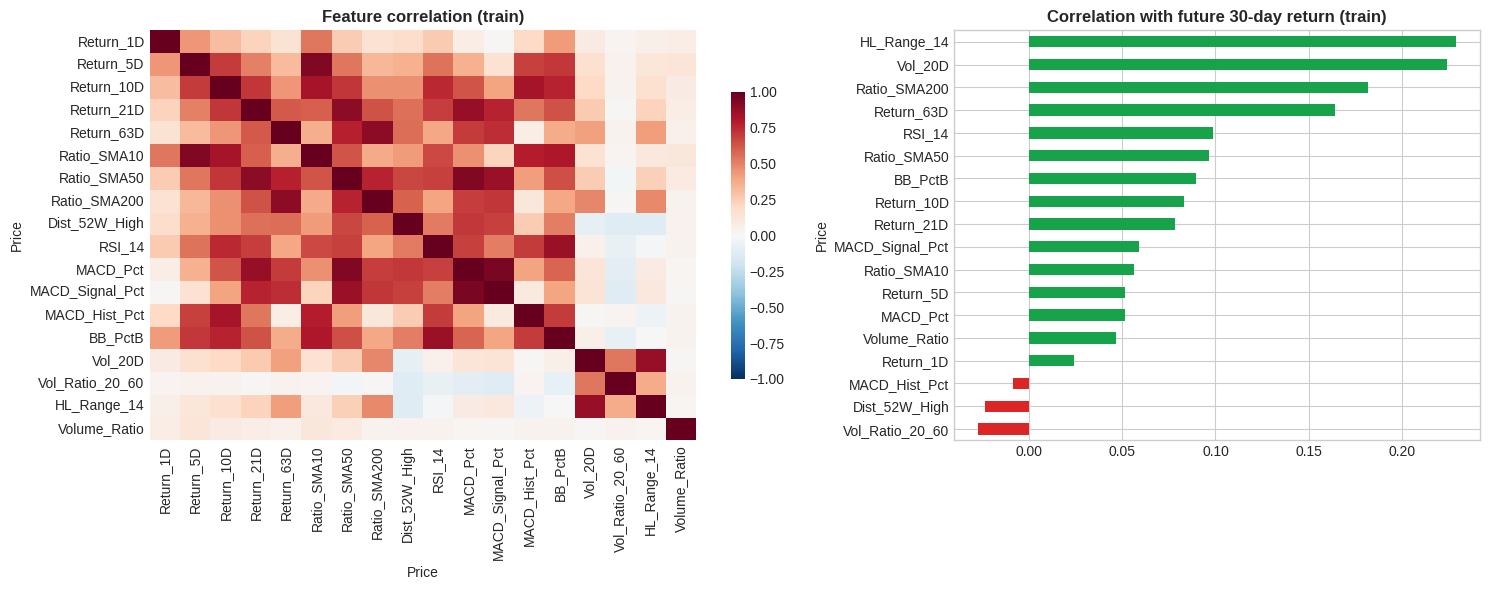

Strongest single-feature correlation with future return: 0.229
Highly correlated feature pairs (|r| > 0.85): 9
Price        Price          
MACD_Pct     MACD_Signal_Pct    0.95
Return_5D    Ratio_SMA10        0.93
Ratio_SMA50  MACD_Pct           0.93
Return_21D   Ratio_SMA50        0.90
Return_63D   Ratio_SMA200       0.89
Return_21D   MACD_Pct           0.87
Vol_20D      HL_Range_14        0.87
Ratio_SMA50  MACD_Signal_Pct    0.87
RSI_14       BB_PctB            0.86


In [10]:
# Feature diagnostics on TRAINING data only (looking at test data here would be a subtle form of leakage)
train_block = df_model.loc[train_idx, FEATURE_COLS + ["Future_Return"]]
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(train_block[FEATURE_COLS].corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[0],
            cbar_kws={"shrink": 0.7}, xticklabels=True, yticklabels=True)
axes[0].set_title("Feature correlation (train)")
corr_target = train_block.corr()["Future_Return"].drop("Future_Return").sort_values()
corr_target.plot(kind="barh", ax=axes[1], color=[COLORS[1] if v > 0 else COLORS[-1] for v in corr_target])
axes[1].set_title("Correlation with future 30-day return (train)")
plt.tight_layout(); save_fig("eda_4_feature_correlations"); plt.show()

high_pairs = (train_block[FEATURE_COLS].corr().abs().where(lambda m: np.triu(np.ones(m.shape, bool), 1))
              .stack().loc[lambda s: s > 0.85].sort_values(ascending=False))
print(f"Strongest single-feature correlation with future return: {corr_target.abs().max():.3f}")
print(f"Highly correlated feature pairs (|r| > 0.85): {len(high_pairs)}")
print(high_pairs.round(2).to_string() if len(high_pairs) else "  none")

**Finding 4: Each feature alone has a very weak link with future returns (|r| typically well below 0.1), and several features overlap heavily** (for example the MACD variants and the short-term moving-average ratios).

➡ **Modelling choice:** no single rule will work, so we try models that **combine weak signals non-linearly** (Random Forest, Gradient Boosting). Overlapping features are harmless for trees; for Logistic Regression, **L2 regularisation** (tuned `C`) keeps coefficients stable.

## 6. Models Tried: from baselines to more complex models

**Evaluation helpers.**
- **Signals:** a non-Hold signal is issued only if its class probability is at least the confidence threshold *and* higher than the opposite class. Otherwise the model holds no position.
- **Backtest:** the signal is computed after the close on day *t* and **filled at the close of day *t*+1**, so the first return earned is from close *t*+1 to close *t*+2 (`EXECUTION_LAG = 2`). *The original notebook used `shift(1)`, which effectively traded at the same close the signal was computed from; that is slightly optimistic.* Each unit of position change pays 0.1%, so flipping from short to long costs 0.2%. Buy-and-hold pays one entry fee.
- **Metrics:** classification metrics (macro F1, balanced accuracy, per-class precision, ROC AUC) plus business metrics (Sharpe, CAGR, max drawdown, number of trades).

In [11]:
def signals_from_proba(proba, classes, threshold):
    classes = list(classes)
    p_buy, p_sell = proba[:, classes.index(1)], proba[:, classes.index(-1)]
    sig = np.zeros(len(proba), dtype=int)
    sig[(p_buy >= threshold) & (p_buy > p_sell)] = 1
    sig[(p_sell >= threshold) & (p_sell > p_buy)] = -1
    return sig

def run_backtest(close, signals, lag=EXECUTION_LAG, fee=TRANSACTION_FEE, long_only=LONG_ONLY, capital=INITIAL_CAPITAL):
    bt = pd.DataFrame({"Close": close.values, "Signal": np.asarray(signals)}, index=close.index)
    if long_only:
        bt["Signal"] = bt["Signal"].clip(lower=0)
    bt["Position"] = bt["Signal"].shift(lag).fillna(0)
    bt["Stock_Return"] = bt["Close"].pct_change().fillna(0)
    bt["Turnover"] = bt["Position"].diff().abs().fillna(bt["Position"].abs())
    bt["Strategy_Return"] = bt["Position"] * bt["Stock_Return"] - bt["Turnover"] * fee
    bt["BuyHold_Return"] = bt["Stock_Return"]
    bt.iloc[0, bt.columns.get_loc("BuyHold_Return")] -= fee
    bt["Strategy_Equity"] = capital * (1 + bt["Strategy_Return"]).cumprod()
    bt["BuyHold_Equity"] = capital * (1 + bt["BuyHold_Return"]).cumprod()
    return bt

def financial_metrics(r, capital=INITIAL_CAPITAL, rf=RISK_FREE_RATE):
    r = pd.Series(r).fillna(0)
    equity = capital * (1 + r).cumprod()
    years = len(r) / 252
    sd = r.std()
    excess = r - rf / 252
    downside = np.sqrt((np.minimum(r, 0) ** 2).mean())
    return {
        "Total Return": equity.iloc[-1] / capital - 1,
        "CAGR": (equity.iloc[-1] / capital) ** (1 / years) - 1,
        "Volatility": sd * np.sqrt(252),
        "Sharpe": excess.mean() / sd * np.sqrt(252) if sd > 1e-12 else np.nan,
        "Sortino": excess.mean() / downside * np.sqrt(252) if downside > 1e-12 else np.nan,
        "Max Drawdown": (equity / equity.cummax() - 1).min(),
    }

def evaluate(model, X, y, idx, threshold, name=""):
    proba = model.predict_proba(X)
    sig = signals_from_proba(proba, model.classes_, threshold)
    bt = run_backtest(df_model.loc[idx, "Close"], sig)
    fm = financial_metrics(bt["Strategy_Return"])
    try:
        auc = roc_auc_score(y, proba, multi_class="ovr", average="macro", labels=list(model.classes_))
    except ValueError:
        auc = np.nan
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y, sig),
        "Balanced Acc": balanced_accuracy_score(y, sig),
        "Macro F1": f1_score(y, sig, average="macro", labels=[-1, 0, 1], zero_division=0),
        "Buy Precision": precision_score(y, sig, labels=[1], average="macro", zero_division=0),
        "Sell Precision": precision_score(y, sig, labels=[-1], average="macro", zero_division=0),
        "ROC AUC (OvR)": auc,
        "Sharpe": fm["Sharpe"], "CAGR": fm["CAGR"], "Max Drawdown": fm["Max Drawdown"],
        "Trades": int((bt["Turnover"] > 0).sum()),
        "% Days in Market": (bt["Position"] != 0).mean(),
    }
    return row, sig, proba, bt

def buyhold_row(idx, name="Buy & Hold (current process)"):
    bt = run_backtest(df_model.loc[idx, "Close"], np.ones(len(idx), dtype=int))
    fm = financial_metrics(bt["BuyHold_Return"])
    return {"Model": name, "Sharpe": fm["Sharpe"], "CAGR": fm["CAGR"], "Max Drawdown": fm["Max Drawdown"],
            "Trades": 1, "% Days in Market": 1.0}

PCT_COLS = ["Accuracy", "Balanced Acc", "Macro F1", "Buy Precision", "Sell Precision", "CAGR",
            "Max Drawdown", "% Days in Market", "Train Macro F1"]
def show_table(rows):
    t = pd.DataFrame(rows).set_index("Model")
    fmt = {c: "{:.1%}" for c in PCT_COLS if c in t}
    fmt.update({c: "{:.2f}" for c in ("ROC AUC (OvR)", "Sharpe") if c in t})
    fmt.update({c: "{:.0f}" for c in ("Trades",) if c in t})
    return t, t.style.format(fmt, na_rep="–")

### 6.1 Candidate models (default settings), scored on validation (2021–2022)

| Model | Role |
|---|---|
| Buy & Hold | Current process: the bar every model must beat |
| Majority-class `DummyClassifier` | "No-skill" ML baseline: always predicts the most common class |
| Logistic Regression (scaled, L2) | Simple, interpretable linear model |
| Random Forest (original v1 settings) | Bagging ensemble from the first version of this notebook |
| Histogram Gradient Boosting | Boosting ensemble: usually strongest on tabular data |
| XGBoost (`XGBoostShifted` wrapper) | Boosting ensemble, XGBoost library — labels shifted -1/0/1 → 0/1/2 internally (see note below) |

`Train Macro F1` is shown next to the validation scores so that a large gap reveals **overfitting** (high variance).

### 6.1a Why XGBoost needs a wrapper

XGBoost (v3.x) only accepts class labels `0..n-1`. This notebook labels Sell/Hold/Buy as `-1/0/1`, so a plain `XGBClassifier` fails at `.fit()` with `ValueError: Invalid classes ... Expected: [0 1 2], got [-1 0 1]` — verified with xgboost 3.4.1.

`XGBoostShifted` (defined in the imports cell) is a thin sklearn-compatible wrapper around `XGBClassifier`: it shifts labels `+1` for training and `-1` back on `predict`, so `.classes_` stays `[-1, 0, 1]` and `predict_proba` columns line up with it, exactly as `evaluate()` / `signals_from_proba()` expect. It works with `clone()` and `GridSearchCV`.

Two differences from the other candidates:
- **No balanced class weights** — `XGBClassifier` has no `class_weight="balanced"` option.
- **Install first:** `pip install xgboost`, or use the supplied `requirements-xgboost.txt` (original `requirements.txt` + `xgboost>=2.0.0`).


In [12]:
candidate_models = {
    "Majority class (Dummy)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([("scaler", StandardScaler()),
                                     ("clf", LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000))]),
    "Random Forest (v1)": RandomForestClassifier(n_estimators=200, max_depth=4, min_samples_leaf=25,
                                                 class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200,
                                                        class_weight="balanced", random_state=RANDOM_STATE),
    "XGBoost": XGBoostShifted(n_estimators=200, max_depth=3, learning_rate=0.05,
                              subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                              random_state=RANDOM_STATE, n_jobs=-1),
}

rows = [buyhold_row(val_idx)]
fitted_default = {}
for name, model in candidate_models.items():
    m = clone(model).fit(X_train, y_train)
    fitted_default[name] = m
    row, *_ = evaluate(m, X_val, y_val, val_idx, DEFAULT_CONFIDENCE, name)
    train_sig = signals_from_proba(m.predict_proba(X_train), m.classes_, DEFAULT_CONFIDENCE)
    row["Train Macro F1"] = f1_score(y_train, train_sig, average="macro", labels=[-1, 0, 1], zero_division=0)
    rows.append(row)

default_table, styled = show_table(rows)
default_table.to_csv(f"{OUTPUT_DIR}/model_comparison_default.csv")
print(f"Validation period, confidence threshold = {DEFAULT_CONFIDENCE}")
styled

Validation period, confidence threshold = 0.45


,Sharpe,CAGR,Max Drawdown,Trades,% Days in Market,Accuracy,Balanced Acc,Macro F1,Buy Precision,Sell Precision,ROC AUC (OvR),Train Macro F1
Model,,,,,,,,,,,,
Buy & Hold (current process),0.03,-13.1%,-56.7%,1,100.0%,–,–,–,–,–,–,–
Majority class (Dummy),0.02,-13.5%,-56.7%,1,99.6%,37.4%,33.3%,18.2%,37.4%,0.0%,0.50,20.9%
Logistic Regression,0.69,26.6%,-39.4%,53,51.4%,30.2%,33.2%,26.7%,40.7%,85.7%,0.49,42.2%
Random Forest (v1),0.29,5.3%,-38.9%,43,39.3%,23.0%,29.2%,19.6%,31.9%,0.0%,0.42,38.9%
Gradient Boosting,0.31,4.9%,-44.8%,88,76.7%,31.1%,31.2%,26.1%,33.0%,45.7%,0.47,88.9%
XGBoost,-0.34,-26.7%,-58.0%,54,81.8%,31.1%,30.0%,22.3%,34.2%,33.3%,0.48,80.2%


**How to read this table:** a model only earns its complexity if it beats **both** baselines: higher macro F1 than the Dummy, and higher Sharpe (or smaller drawdown) than Buy & Hold. A big gap between `Train Macro F1` and `Macro F1` means the model memorised noise.

## 7. Hyperparameter Tuning

- **Method:** `GridSearchCV` with **`TimeSeriesSplit(n_splits=30, gap=30)`** on the **training set only**: each fold trains on earlier years and validates on the next block, with a 30-day gap so overlapping labels cannot leak.
- **Scoring:** macro F1 (treats Buy, Hold and Sell equally, matching Finding 2).
- **The test set stays sealed.** Model choice and confidence threshold are decided on the 2021–2022 validation set.

In [13]:
tscv = TimeSeriesSplit(n_splits=N_CV_SPLITS, gap=FUTURE_PERIOD)

search_spaces = {
    "Logistic Regression": (
        Pipeline([("scaler", StandardScaler()),
                  ("clf", LogisticRegression(class_weight="balanced", max_iter=5000))]),
        {"clf__C": [0.001, 0.01, 0.1, 1.0, 10.0]}),
    "Random Forest": (
        RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=1),
        {"max_depth": [3, 4, 6, 8], "min_samples_leaf": [10, 25, 50], "max_features": ["sqrt", 0.5]}),
    "Gradient Boosting": (
        HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        {"learning_rate": [0.03, 0.1], "max_depth": [2, 3, 5], "max_iter": [100, 300], "l2_regularization": [0.0, 1.0]}),
    "XGBoost": (
        XGBoostShifted(random_state=RANDOM_STATE, n_jobs=-1),
        {"learning_rate": [0.03, 0.1], "max_depth": [2, 3, 5],
         "n_estimators": [100, 300], "subsample": [0.8, 1.0]}),
}

searches = {}
for name, (est, grid) in search_spaces.items():
    gs = GridSearchCV(est, grid, cv=tscv, scoring="f1_macro", n_jobs=-1, return_train_score=True)
    gs.fit(X_train, y_train)
    searches[name] = gs
    best = gs.cv_results_
    i = gs.best_index_
    print(f"{name:20s} best CV macro F1 = {gs.best_score_:.3f} (train {best['mean_train_score'][i]:.3f}, "
          f"fold std {best['std_test_score'][i]:.3f})  params = {gs.best_params_}")

Logistic Regression  best CV macro F1 = 0.316 (train 0.568, fold std 0.038)  params = {'clf__C': 1.0}
Random Forest        best CV macro F1 = 0.307 (train 0.808, fold std 0.063)  params = {'max_depth': 6, 'max_features': 0.5, 'min_samples_leaf': 10}
Gradient Boosting    best CV macro F1 = 0.332 (train 1.000, fold std 0.078)  params = {'l2_regularization': 0.0, 'learning_rate': 0.1, 'max_depth': 5, 'max_iter': 100}
XGBoost              best CV macro F1 = 0.320 (train 0.922, fold std 0.069)  params = {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 300, 'subsample': 1.0}


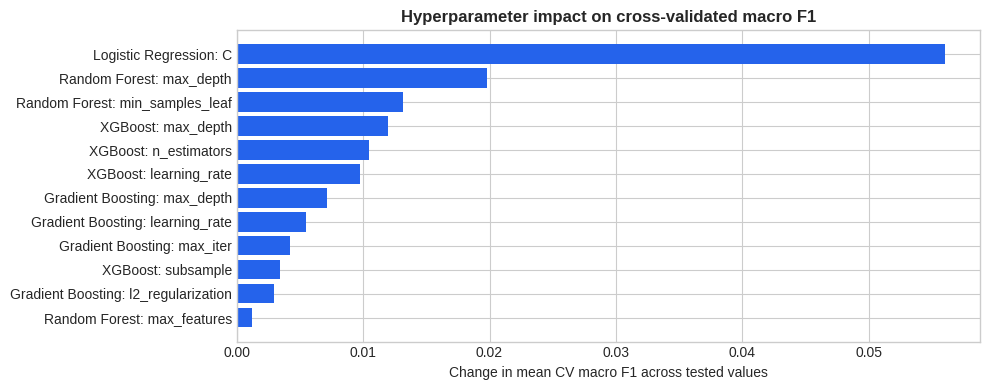

,Model,Hyperparameter,Effect (max - min CV F1),Best value,Mean CV F1 by value
0,Logistic Regression,C,0.056006,1.0,"{'0.001': 0.26, '0.01': 0.275, '0.1': 0.315, '..."
1,Random Forest,max_depth,0.019809,6,"{'3': 0.277, '4': 0.288, '6': 0.297, '8': 0.293}"
2,Random Forest,min_samples_leaf,0.013154,10,"{'10': 0.294, '25': 0.29, '50': 0.281}"
3,XGBoost,max_depth,0.011941,5,"{'2': 0.301, '3': 0.31, '5': 0.313}"
4,XGBoost,n_estimators,0.010466,300,"{'100': 0.303, '300': 0.314}"
5,XGBoost,learning_rate,0.009722,0.1,"{'0.03': 0.304, '0.1': 0.313}"
6,Gradient Boosting,max_depth,0.007165,5,"{'2': 0.319, '3': 0.32, '5': 0.326}"
7,Gradient Boosting,learning_rate,0.005488,0.1,"{'0.03': 0.319, '0.1': 0.324}"
8,Gradient Boosting,max_iter,0.004217,300,"{'100': 0.319, '300': 0.324}"
9,XGBoost,subsample,0.003449,1.0,"{'0.8': 0.307, '1.0': 0.31}"


In [14]:
# Which hyperparameter mattered most? Effect = spread of mean CV score across that parameter's values
effects = []
for name, gs in searches.items():
    res = pd.DataFrame(gs.cv_results_)
    for p in gs.param_grid:
        by_val = res.groupby(res[f"param_{p}"].astype(str))["mean_test_score"].mean()
        effects.append({"Model": name, "Hyperparameter": p.replace("clf__", ""),
                        "Effect (max - min CV F1)": by_val.max() - by_val.min(),
                        "Best value": by_val.idxmax(), "Mean CV F1 by value": by_val.round(3).to_dict()})
effects = pd.DataFrame(effects).sort_values("Effect (max - min CV F1)", ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
labels = effects["Model"] + ": " + effects["Hyperparameter"]
ax.barh(labels[::-1], effects["Effect (max - min CV F1)"][::-1], color=COLORS["strategy"])
ax.set_title("Hyperparameter impact on cross-validated macro F1")
ax.set_xlabel("Change in mean CV macro F1 across tested values")
plt.tight_layout(); save_fig("tuning_hyperparameter_effects"); plt.show()
effects.reset_index(drop=True)

**Interpreting the tuning results.** In noisy financial data, the parameters that control **model complexity** (tree depth, minimum leaf size, regularisation strength `C`, learning rate) usually matter most. Shallower trees, larger leaves and stronger regularisation reduce **variance**: the model stops memorising day-to-day noise. Compare `best CV` with `train` scores above: a large gap is the overfitting signature from the bias–variance lesson.

In [15]:
rows = [buyhold_row(val_idx), {**evaluate(fitted_default["Majority class (Dummy)"], X_val, y_val, val_idx,
                                          DEFAULT_CONFIDENCE, "Majority class (Dummy)")[0]}]
for name, gs in searches.items():
    rows.append(evaluate(gs.best_estimator_, X_val, y_val, val_idx, DEFAULT_CONFIDENCE, f"{name} (tuned)")[0])
tuned_table, styled = show_table(rows)
tuned_table.to_csv(f"{OUTPUT_DIR}/model_comparison_tuned.csv")

ml_rows = tuned_table[tuned_table.index.str.contains("tuned")]
key = SELECTION_METRIC if ml_rows[SELECTION_METRIC].notna().any() else "Macro F1"
best_label = ml_rows[key].idxmax()
best_name = best_label.replace(" (tuned)", "")
best_model_trainfit = searches[best_name].best_estimator_
print(f"Selected on validation {key}: {best_label}")
styled

Selected on validation Sharpe: Logistic Regression (tuned)


,Sharpe,CAGR,Max Drawdown,Trades,% Days in Market,Accuracy,Balanced Acc,Macro F1,Buy Precision,Sell Precision,ROC AUC (OvR)
Model,,,,,,,,,,,
Buy & Hold (current process),0.03,-13.1%,-56.7%,1,100.0%,–,–,–,–,–,–
Majority class (Dummy),0.02,-13.5%,-56.7%,1,99.6%,37.4%,33.3%,18.2%,37.4%,0.0%,0.50
Logistic Regression (tuned),0.69,26.6%,-39.4%,53,51.4%,30.2%,33.2%,26.7%,40.7%,85.7%,0.49
Random Forest (tuned),0.12,-4.1%,-45.1%,68,54.5%,22.6%,25.5%,20.1%,28.8%,33.3%,0.41
Gradient Boosting (tuned),-0.21,-21.8%,-58.7%,90,79.9%,32.1%,30.9%,26.4%,34.2%,47.7%,0.47
XGBoost (tuned),-0.25,-23.3%,-53.4%,51,83.5%,29.8%,28.1%,20.0%,33.3%,30.8%,0.47


### 7.1 Choosing the confidence threshold (on validation)

Like moving the 0.5 cut-off in the churn lesson, the confidence threshold trades **how often we trade** against **how reliable each trade is**. We sweep thresholds on the validation set and choose the one with the best Sharpe, requiring at least `MIN_TRADES` position changes so a lucky handful of trades cannot win.

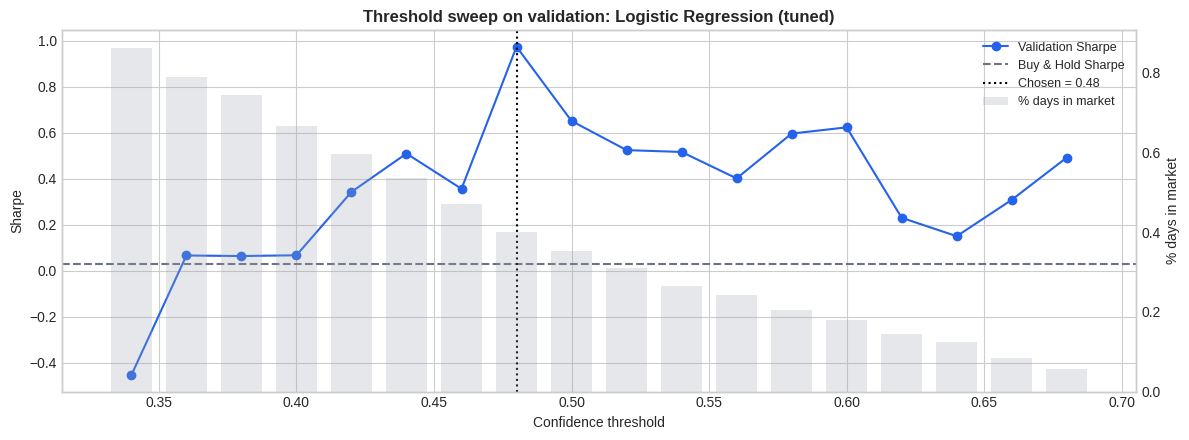

Chosen confidence threshold: 0.48


,Threshold,Sharpe,CAGR,Macro F1,Trades,% Days in Market
0,0.340000,-0.45,-34.0%,26.2%,60,86%
1,0.360000,0.07,-9.5%,28.1%,57,79%
2,0.380000,0.06,-9.2%,29.3%,55,74%
3,0.400000,0.07,-7.5%,29.2%,72,67%
4,0.420000,0.34,7.2%,29.2%,65,60%
5,0.440000,0.51,16.3%,27.4%,59,53%
6,0.460000,0.36,8.4%,25.8%,61,47%
7,0.480000,0.97,40.4%,24.7%,47,40%
8,0.500000,0.65,22.4%,22.6%,49,35%
9,0.520000,0.52,16.1%,21.3%,37,31%


In [16]:
val_proba = best_model_trainfit.predict_proba(X_val)
sweep = []
for th in np.round(np.arange(0.34, 0.70, 0.02), 2):
    sig = signals_from_proba(val_proba, best_model_trainfit.classes_, th)
    bt = run_backtest(df_model.loc[val_idx, "Close"], sig)
    fm = financial_metrics(bt["Strategy_Return"])
    sweep.append({"Threshold": th, "Sharpe": fm["Sharpe"], "CAGR": fm["CAGR"],
                  "Macro F1": f1_score(y_val, sig, average="macro", labels=[-1, 0, 1], zero_division=0),
                  "Trades": int((bt["Turnover"] > 0).sum()), "% Days in Market": (bt["Position"] != 0).mean()})
sweep = pd.DataFrame(sweep)
eligible = sweep[(sweep["Trades"] >= MIN_TRADES) & sweep["Sharpe"].notna()]
BEST_THRESHOLD = float(eligible.loc[eligible["Sharpe"].idxmax(), "Threshold"]) if len(eligible) else DEFAULT_CONFIDENCE

fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.plot(sweep["Threshold"], sweep["Sharpe"], "o-", color=COLORS["strategy"], label="Validation Sharpe")
ax1.axhline(buyhold_row(val_idx)["Sharpe"], color=COLORS["buyhold"], ls="--", label="Buy & Hold Sharpe")
ax1.axvline(BEST_THRESHOLD, color="black", ls=":", label=f"Chosen = {BEST_THRESHOLD:.2f}")
ax1.set_xlabel("Confidence threshold"); ax1.set_ylabel("Sharpe")
ax2 = ax1.twinx()
ax2.bar(sweep["Threshold"], sweep["% Days in Market"], width=0.015, alpha=0.25, color=COLORS[0], label="% days in market")
ax2.set_ylabel("% days in market"); ax2.grid(False)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="best", fontsize=9)
ax1.set_title(f"Threshold sweep on validation: {best_label}")
plt.tight_layout(); save_fig("tuning_threshold_sweep"); plt.show()
print(f"Chosen confidence threshold: {BEST_THRESHOLD:.2f}")
sweep.style.format({"Sharpe": "{:.2f}", "CAGR": "{:.1%}", "Macro F1": "{:.1%}", "% Days in Market": "{:.0%}"}, na_rep="–")

## 8. Final Evaluation on the Sealed Test Set (2023–2024)

The chosen model and threshold are **refitted once on train + validation** (2012–2022, purged before 2023) and scored **once** on the test set. Nothing below is used to change the model.

**Metrics and why they fit the business problem**

| Metric | Why |
|---|---|
| **Sharpe ratio** (primary) | The desk cares about return per unit of risk, after costs, not raw accuracy. |
| **Max drawdown** | Clients feel losses from peaks; drawdown is a key risk limit. |
| **Buy / Sell precision** | When the model says "trade", how often is it right? False signals cost fees and money. |
| **Macro F1, balanced accuracy** | Classification quality with every class counted equally (accuracy alone can be fooled, as with the Dummy). |
| **ROC AUC (one-vs-rest)** | Threshold-free check of how well probabilities *rank* days. 0.5 means no skill. |

In [17]:
final_model = clone(best_model_trainfit).fit(df_model.loc[trval_idx, FEATURE_COLS], df_model.loc[trval_idx, "Target"])
test_row, test_sig, test_proba, test_bt = evaluate(final_model, X_test, y_test, test_idx, BEST_THRESHOLD, best_label)
val_row = evaluate(best_model_trainfit, X_val, y_val, val_idx, BEST_THRESHOLD, best_label)[0]

strat_fm = financial_metrics(test_bt["Strategy_Return"])
bh_fm = financial_metrics(test_bt["BuyHold_Return"])

print(f"Model: {best_label} | threshold {BEST_THRESHOLD:.2f} | data: {DATA_SOURCE}\n")
print(classification_report(y_test, test_sig, labels=[-1, 0, 1],
                            target_names=[CLASS_NAMES[c] for c in (-1, 0, 1)], zero_division=0))

compare = pd.DataFrame({
    "Validation (2021-22)": {k: val_row[k] for k in ("Macro F1", "Buy Precision", "Sell Precision", "ROC AUC (OvR)", "Sharpe", "CAGR", "Max Drawdown", "Trades")},
    "Test (2023-26)":       {k: test_row[k] for k in ("Macro F1", "Buy Precision", "Sell Precision", "ROC AUC (OvR)", "Sharpe", "CAGR", "Max Drawdown", "Trades")},
})
compare.to_csv(f"{OUTPUT_DIR}/validation_vs_test.csv")
compare

Model: Logistic Regression (tuned) | threshold 0.48 | data: Yahoo Finance (downloaded)

              precision    recall  f1-score   support

   Sell (-1)       0.22      0.02      0.03       324
    Hold (0)       0.28      0.79      0.41       231
     Buy (1)       0.56      0.36      0.44       354

    accuracy                           0.35       909
   macro avg       0.35      0.39      0.29       909
weighted avg       0.36      0.35      0.29       909



,Validation (2021-22),Test (2023-26)
Macro F1,0.246856,0.293464
Buy Precision,0.418478,0.556034
Sell Precision,0.857143,0.217391
ROC AUC (OvR),0.493753,0.615395
Sharpe,0.974019,0.937856
CAGR,0.404481,0.337837
Max Drawdown,-0.293556,-0.472161
Trades,47.000000,76.000000


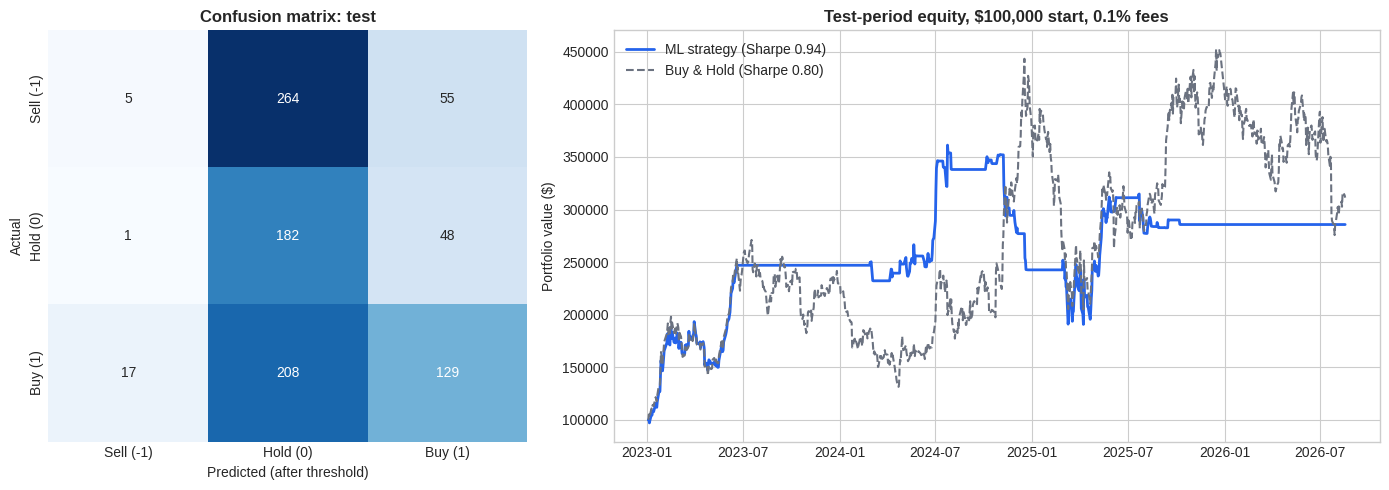

,ML Strategy,Buy & Hold
Total Return,185.7%,211.3%
CAGR,33.8%,37.0%
Volatility,35.5%,57.9%
Sharpe,0.94,0.80
Sortino,1.53,1.22
Max Drawdown,-47.2%,-53.8%
Trades,76,1
% Days in Market,28.1%,100.0%


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.6]})
cm = confusion_matrix(y_test, test_sig, labels=[-1, 0, 1])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=[CLASS_NAMES[c] for c in (-1, 0, 1)], yticklabels=[CLASS_NAMES[c] for c in (-1, 0, 1)])
axes[0].set_xlabel("Predicted (after threshold)"); axes[0].set_ylabel("Actual"); axes[0].set_title("Confusion matrix: test")

axes[1].plot(test_bt.index, test_bt["Strategy_Equity"], color=COLORS["strategy"], lw=2,
             label=f"ML strategy (Sharpe {strat_fm['Sharpe']:.2f})")
axes[1].plot(test_bt.index, test_bt["BuyHold_Equity"], color=COLORS["buyhold"], ls="--",
             label=f"Buy & Hold (Sharpe {bh_fm['Sharpe']:.2f})")
axes[1].set_title(f"Test-period equity, ${INITIAL_CAPITAL:,.0f} start, {TRANSACTION_FEE:.1%} fees")
axes[1].set_ylabel("Portfolio value ($)"); axes[1].legend()
plt.tight_layout(); save_fig("test_confusion_and_equity"); plt.show()

fin_table = pd.DataFrame({"ML Strategy": strat_fm, "Buy & Hold": bh_fm})
fin_table.loc["Trades"] = [test_row["Trades"], 1]
fin_table.loc["% Days in Market"] = [test_row["% Days in Market"], 1.0]
fin_table.to_csv(f"{OUTPUT_DIR}/test_financial_metrics.csv")
styler = fin_table.style
for r in fin_table.index:
    styler = styler.format({"Sharpe": "{:.2f}", "Sortino": "{:.2f}", "Trades": "{:.0f}"}.get(r, "{:.1%}"),
                           subset=pd.IndexSlice[[r], :])
styler

### 8.1 Error analysis: where does the model fail?

1. **By volatility regime** (cut-offs set on *training* data): does the model only work in calm markets?
2. **By quarter**: is performance stable, or driven by one lucky period?
3. **Signal quality**: what actually happened after Buy and Sell signals, and how often did the model call the exact opposite direction?

/tmp/ipykernel_3485/4040943428.py:17: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_regime = ea.groupby("Vol regime", observed=False).apply(segment_stats)


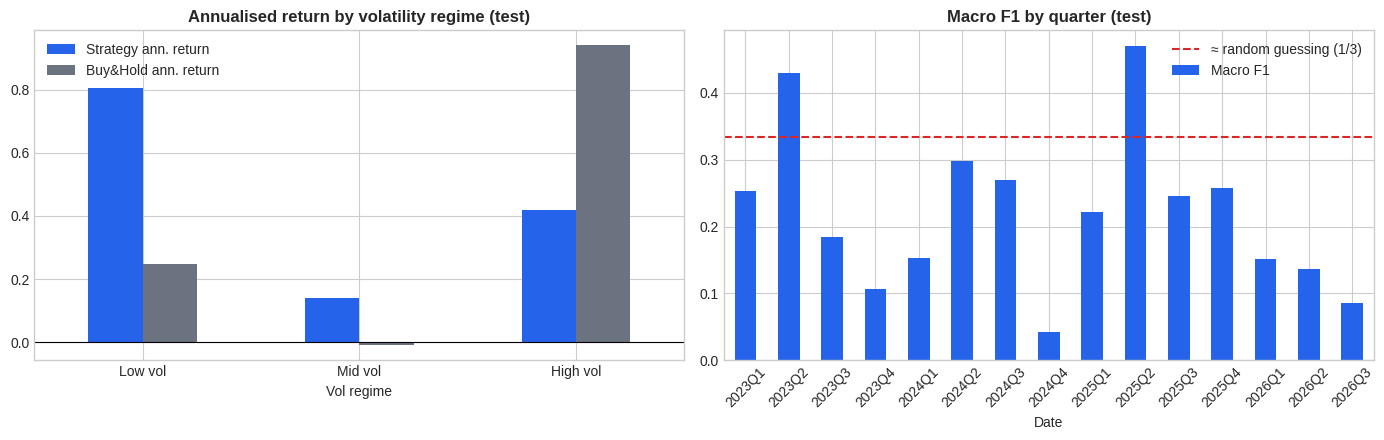

Signal quality (test):


,Signals issued,Avg future 5d return,% future return > 0,Opposite-direction errors
Buy (1),232.0,0.154562,0.672414,55.0
Hold (0),654.0,0.007456,0.451070,NaN
Sell (-1),23.0,0.212096,0.739130,17.0


,Days,Macro F1,Strategy ann. return,Buy&Hold ann. return
Vol regime,,,,
Low vol,108,27.0%,80.7%,24.8%
Mid vol,361,30.0%,13.8%,-1.1%
High vol,440,28.7%,41.8%,94.1%


In [19]:
ea = df_model.loc[test_idx, ["Close", "Future_Return", "Target", "Vol_20D"]].copy()
ea["Signal"] = test_sig
ea["Strategy_Return"] = test_bt["Strategy_Return"]
ea["BuyHold_Return"] = test_bt["BuyHold_Return"]

lo, hi = df_model.loc[train_idx, "Vol_20D"].quantile([1 / 3, 2 / 3])
ea["Vol regime"] = pd.cut(ea["Vol_20D"], [-np.inf, lo, hi, np.inf], labels=["Low vol", "Mid vol", "High vol"])

def segment_stats(g):
    return pd.Series({
        "Days": len(g),
        "Macro F1": f1_score(g["Target"], g["Signal"], average="macro", labels=[-1, 0, 1], zero_division=0),
        "Strategy ann. return": g["Strategy_Return"].mean() * 252,
        "Buy&Hold ann. return": g["BuyHold_Return"].mean() * 252,
    })

by_regime = ea.groupby("Vol regime", observed=False).apply(segment_stats)
by_quarter = ea.groupby(ea.index.to_period("Q")).apply(segment_stats)
by_regime.to_csv(f"{OUTPUT_DIR}/error_by_regime.csv"); by_quarter.to_csv(f"{OUTPUT_DIR}/error_by_quarter.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
by_regime[["Strategy ann. return", "Buy&Hold ann. return"]].plot(kind="bar", ax=axes[0], color=[COLORS["strategy"], COLORS["buyhold"]], rot=0)
axes[0].set_title("Annualised return by volatility regime (test)"); axes[0].axhline(0, color="black", lw=0.8)
by_quarter["Macro F1"].plot(kind="bar", ax=axes[1], color=COLORS["strategy"], rot=45)
axes[1].axhline(1 / 3, color=COLORS[-1], ls="--", label="≈ random guessing (1/3)")
axes[1].set_title("Macro F1 by quarter (test)"); axes[1].legend()
plt.tight_layout(); save_fig("error_analysis_segments"); plt.show()

signal_quality = pd.DataFrame({
    CLASS_NAMES[s]: {
        "Signals issued": int((ea["Signal"] == s).sum()),
        "Avg future 5d return": ea.loc[ea["Signal"] == s, "Future_Return"].mean(),
        "% future return > 0": (ea.loc[ea["Signal"] == s, "Future_Return"] > 0).mean(),
        "Opposite-direction errors": int(((ea["Signal"] == s) & (ea["Target"] == -s)).sum()) if s != 0 else np.nan,
    } for s in (1, 0, -1)}).T
print("Signal quality (test):")
display(signal_quality)
display(by_regime.style.format({"Macro F1": "{:.1%}", "Strategy ann. return": "{:.1%}", "Buy&Hold ann. return": "{:.1%}", "Days": "{:.0f}"}))

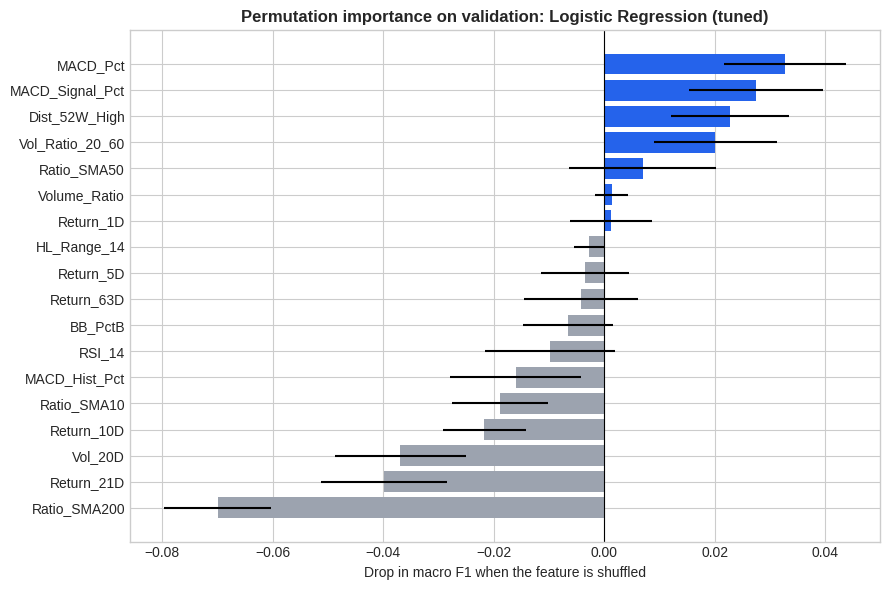

Top 5 features: MACD_Pct, MACD_Signal_Pct, Dist_52W_High, Vol_Ratio_20_60, Ratio_SMA50


In [20]:
# What drives the predictions? Permutation importance on VALIDATION (model fitted on train only)
pi = permutation_importance(best_model_trainfit, X_val, y_val, scoring="f1_macro", n_repeats=10,
                            random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURE_COLS).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(imp.index, imp.values, xerr=pd.Series(pi.importances_std, index=FEATURE_COLS)[imp.index],
        color=[COLORS["strategy"] if v > 0 else COLORS[0] for v in imp.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_title(f"Permutation importance on validation: {best_label}")
ax.set_xlabel("Drop in macro F1 when the feature is shuffled")
plt.tight_layout(); save_fig("feature_importance"); plt.show()
print("Top 5 features:", ", ".join(imp.sort_values(ascending=False).index[:5]))